## 1. `date_score()` → date_score, remove

In [6]:
import math
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
nulldurchgang=5

tau = 1 * (60 - nulldurchgang) / np.arctanh(0.8)     # ab welchem Abstand (Tage) Punkte als "nah" gelten
k = 2    # wie schnell amplification Richtung 4 geht

def date_score(amplification,dist_last):
    return 10  *  np.tanh(amplification / tau * (np.asarray(dist_last) - nulldurchgang))


def smoothDensity(dates, tau=tau):
    d = pd.to_datetime(pd.Series(dates)).values.astype("datetime64[D]").astype(float)
    if len(d) < 2:
        return 0.0
    diff = np.abs(d[:, None] - d[None, :])   # Abstand jedes Punkts zu jedem anderen
    w = np.exp(-diff / tau)                  # nah → Gewicht ≈ 1, weit → ≈ 0
    np.fill_diagonal(w, 0)                   # sich selbst nicht mitzählen
    return w.sum(axis=1).max()               # dichtester Punkt bestimmt den Score

def amplification(score,repeat_score, k=k):
    s = np.asarray(score, dtype=float)
    return (1 + 3 * (1 - np.exp(-s / k)))*repeat_score      # 0 → 1, steigt glatt Richtung 4

LEVELS = {0: "o", 0.5: "s", 0.8: "^", 0.9: "D"}   # Anteil vom Maximum : Marker
MAX_SCORE = 10

def plot_date_score(ax, amplification, dist_last, label=None, **kwargs):
    """Zeichnet eine date_score-Kurve und markiert Nulldurchgang, 50 %, 80 %, 90 %."""
    line, = ax.plot(dist_last, date_score(amplification, dist_last),
                    label=label, **kwargs)
    c = amplification / tau
    for p, m in LEVELS.items():
        x = nulldurchgang + np.arctanh(p) / c
        if x <= dist_last.max():
            ax.plot(x, p * MAX_SCORE, m, color=line.get_color(), ms=7)
    return line

def style_axes(ax, title):
    """Hilfslinien, Marker-Legende und Beschriftung."""
    for p, m in LEVELS.items():
        ax.plot([], [], m, color="black", ls="",
                label="Nulldurchgang" if p == 0 else f"{p:.0%} von max")
        ax.axhline(p * MAX_SCORE, color="gray", lw=0.5, ls=":")
    ax.axvline(nulldurchgang, color="gray", lw=0.8, ls="--")
    ax.set_xlabel("dist_last")
    ax.set_ylabel("date_score")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

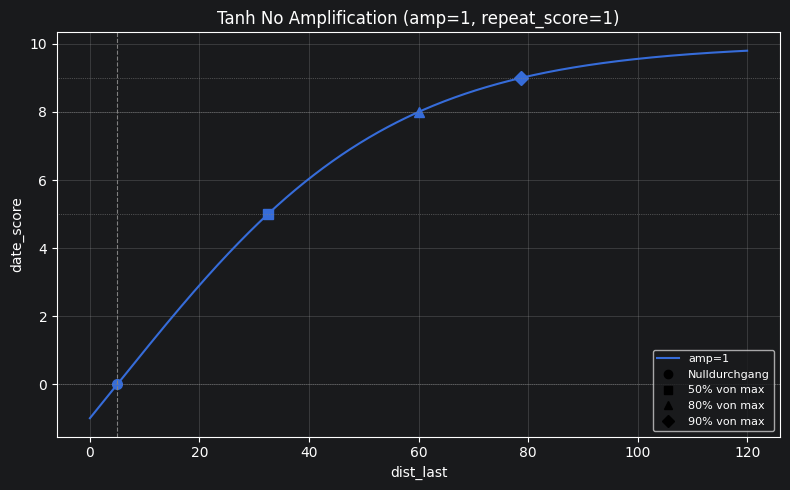

In [7]:
dist_last = np.linspace(0, 120, 500)
fig, ax = plt.subplots(figsize=(8, 5))
plot_date_score(ax, amplification=1, dist_last=dist_last, label="amp=1")
style_axes(ax, "Tanh No Amplification (amp=1, repeat_score=1)")
plt.tight_layout()
plt.show()

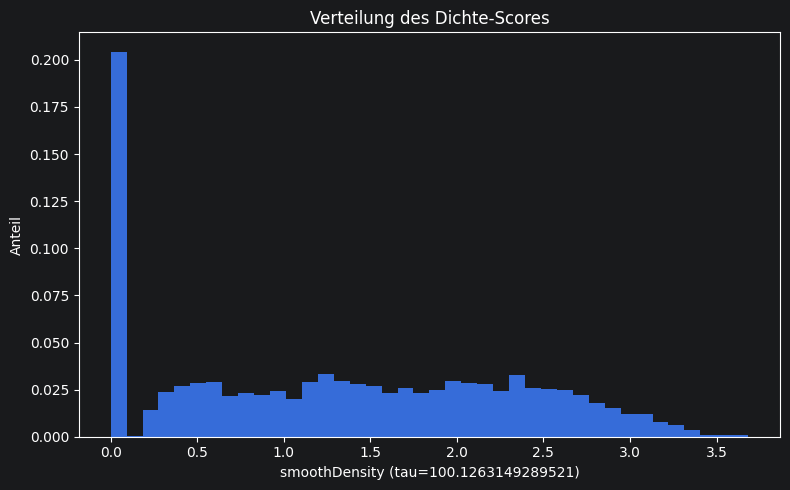

In [3]:
rng = np.random.default_rng(0)
ergebnisse = []
for _ in range(5000):
    n = rng.integers(1, 6)                         # 1 bis 5 Daten
    tage = rng.integers(0, 180, n)                 # zufällig in 6 Monaten
    dates = pd.Timestamp("2026-01-01") + pd.to_timedelta(tage, unit="D")
    ergebnisse.append(smoothDensity(dates, tau=tau))
plt.figure(figsize=(8, 5))
ergebnisse = np.array(ergebnisse)
# Score, ab dem ein bestimmter Faktor erreicht wird


plt.hist(ergebnisse, bins=40, weights=np.ones_like(ergebnisse) / len(ergebnisse))
plt.xlabel(f"smoothDensity (tau={tau})")
plt.ylabel("Anteil")
plt.title("Verteilung des Dichte-Scores")
plt.tight_layout()
plt.show()

In [4]:
scores = np.linspace(0, 10, 300)          # smoothDensity-Score ≈ Anzahl naher Nachbarn

plt.figure(figsize=(8, 5))
plt.plot(scores, amplification(scores, k=k))

plt.axhline(1, color="gray", lw=0.8, ls="--", label="Untergrenze 1")
plt.axhline(4, color="gray", lw=0.8, ls="--", label="Grenzwert 4")

# Score, ab dem ein bestimmter Faktor erreicht wird
for f in [2, 3, 3.5]:
    s = -k * np.log(1 - (f - 1) / 3)
    plt.axvline(s, color="gray", lw=0.5, ls=":")
    plt.scatter(s, f, color="red", zorder=5)
    plt.annotate(f"({s:.2f}, {f})", (s, f),
                 xytext=(8, -14), textcoords="offset points", color="red")

plt.xlabel("density score (smoothDensity)")
plt.ylabel("factor")
plt.title(f"AmplificationScore (k={k})")
plt.ylim(0.8, 4.2)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

TypeError: amplification() missing 1 required positional argument: 'repeat_score'

<Figure size 800x500 with 0 Axes>

In [ ]:


ergebnisse = np.array(ergebnisse)
amps = amplification(ergebnisse, k=k)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    amps,
    bins=40,
    range=(1, 4),
    weights=np.ones_like(amps) / len(amps)
)

ax.set_xlabel(f"Amplification (k={k})")
ax.set_ylabel("Relative Häufigkeit")
ax.set_title("Verteilung des Faktors")

ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()


In [ ]:




base = pd.Timestamp("2026-01-01")
def days(*offsets):
    return [base + pd.Timedelta(days=o) for o in offsets]

# Beispiel-Szenarien statt avg_dists
scenarios = {
    "gleichmäßig, alle 60 T":  days(0, 60, 120, 180, 240),
    "gleichmäßig, alle 28 T":  days(0, 28, 56, 84, 112),
    "gleichmäßig, alle 7 T":   days(0, 7, 14, 21, 28),
    "kleiner Cluster + Rest":  days(0, 2, 4, 90, 180, 270),
    "starker Cluster":         days(0, 1, 2, 3, 4, 200),
}


repeat_scores = [1, 5]
levels = {0: "o", 0.5: "s", 0.8: "^", 0.9: "D"}
max_score = 10


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, repeat_score in zip(axes, repeat_scores):
    for name, dates in scenarios.items():
        score = smoothDensity(dates, tau=tau)
        faktor = amplification(score, k=k)
        plot_date_score(ax, faktor, repeat_score, dist_last,
                        label=f"{name}: dens={score:.2f}, amp={faktor:.2f}")
    style_axes(ax, f"repeat_score = {repeat_score}  (tau={tau}, k={k})")

plt.tight_layout()
plt.show()



## Sanity Checks

Expected behavior. 🟠 = not tested yet; "old" = value from the old test script, re-check here.

| Situation | Expected | Status |
|---|---|---|
| just cooked | removed / 0 | 🟠 old: 0, removed |
| cooked within 4 days (incl. exactly 4) | removed | 🟠 old: removed |
| 5 days ago | not removed | 🟠 |
| cooked rarely, long ago | high (~2·repeat) | 🟠 old: 9.94 |
| normal rhythm, in between | medium | 🟠 old: 5.18 |
| never cooked | medium | 🟠 old: 5.00 |
| higher repeat ⇒ higher score | monotonically increasing | 🟠 |
| longer ago ⇒ higher score | monotonically increasing | 🟠 |
| always in [0, 10] | – | 🟠 |